# Семинар к лабораторной работе № 18 «Пассивные электрические цепи»

*Курс «Радиотехнические цепи и сигналы» · МФТИ · по материалам лабораторной работы
«Пассивные электрические цепи» (А. А. Григорьев, И. В. Филатов, МФТИ, 2020) и книги
Юкио Сато «Занимательная цифровая обработка сигналов»*

**Цель занятия** (слайды 2–3): математический аппарат лабораторной работы № 18 — ключевой
для дисциплин «радиотехника» и «цифровая обработка сигналов». Задача семинара — преодолеть
неизбежный психологический барьер и получить **интуитивное** понимание используемого
математического аппарата: как пройденного (матанализ, линейная алгебра, дифференциальные
уравнения), так и перспективного (ТФКП — теория функций комплексной переменной).
Мы хотим увидеть целостную картину: ключевые методы анализа линейных электрических цепей
и их взаимосвязь, а закончить практическим примером.

**План семинара** — ровно как в презентации:

1. Математический ликбез: комплексные числа → элементы линейной алгебры → ряды Фурье → преобразование Фурье
2. Методы анализа линейных систем на примере RC-цепи: дифференциальные уравнения, преобразование Лапласа, δ-функция, импульсная и переходная характеристики, интеграл Дюамеля, спектральный анализ
3. Элементы цифровой фильтрации: сглаживание (blur)
4. Приложения и литература

> Каждый раздел этого ноутбука соответствует слайдам презентации и содержит: понятное
> объяснение (markdown с формулами) + живой код на Python (NumPy/SciPy/SymPy/Matplotlib),
> который можно и нужно перезапускать и менять. Формулы везде «как на слайдах».


In [59]:
import numpy as np
import matplotlib.pyplot as plt
import cmath
import sympy as sp
from scipy.integrate import solve_ivp
import scipy

plt.rcParams['figure.figsize'] = (9, 3.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 9
np.random.seed(42)

print('numpy', np.__version__, '| scipy', scipy.__version__,
      '| sympy', sp.__version__, '| matplotlib', plt.matplotlib.__version__)

numpy 2.5.1 | scipy 1.18.0 | sympy 1.14.0 | matplotlib 3.11.0


---
## 1. Мир сквозь «комплексные очки» *(слайды 4–8)*

Почему комплексные числа — это не «страшная выдумка математиков», а самый естественный
язык теории цепей? Потому что **комплексное число — это точка (или вектор) на плоскости**,
а операции над ними — это привычная геометрия: сложение векторов и повороты с растяжением.

**Три лица одного числа.** Одно и то же комплексное число $z$ можно записать тремя способами:

$$z = a + jb = |z|(\cos\varphi + j\sin\varphi) = |z|\,e^{j\varphi}$$

* **алгебраическая форма** $a + jb$ — удобна для сложения и вычитания;
* **тригонометрическая форма** — видно модуль $|z|=\sqrt{a^2+b^2}$ и аргумент $\varphi = \operatorname{arctg}(b/a)$;
* **показательная (экспоненциальная) форма** $|z|e^{j\varphi}$ — «самая важная для Лапласа»:
формула Эйлера сворачивает тригонометрию в компактную «молнию»:

$$\boxed{\,e^{j\varphi} = \cos\varphi + j\sin\varphi\,}$$

**Геометрия операций:**
* сложение $(z_1+z_2)$ — правило параллелограмма;
* умножение $z_1 z_2 = |z_1||z_2|\,e^{j(\varphi_1+\varphi_2)}$ — **модули перемножаются, аргументы складываются** (поворот + растяжение!). Именно поэтому гармонический сигнал $e^{j\omega t}$, проходя через цепь, лишь умножается на комплексное число — меняет амплитуду и фазу, но не форму.

**Два фокуса со слайда 8** — что «видит» человек в комплексных очках:

1. $\sqrt{-9} = \pm j3$ — конечно! Ведь $-9 = 9\,e^{j(\pi + 2\pi k)}$, значит
   $z_k = 3\,e^{j(\pi/2 + \pi k)} = \pm 3j$.
2. Уравнение $\cos x = 2$ **имеет** решения — но комплексные:
   $\cos x = \tfrac{e^{jx}+e^{-jx}}{2} = 2\;\Rightarrow\; y^2-4y+1=0$, где $y=e^{jx}$,
   $y = 2\pm\sqrt{3}$, откуда $x = -j\ln(2\pm\sqrt{3})$.


In [60]:
# Три лица одного числа
z = 3 + 4j
r, phi = abs(z), cmath.phase(z)
print(f'z = {z}')
print(f'|z| = {r},  φ = {phi:.4f} рад = {np.degrees(phi):.2f}°')
print(f'проверка: {r*np.cos(phi):.1f} + {r*np.sin(phi):.1f}j')

# Формула Эйлера: e^{jφ} = cos φ + j sin φ — проверим численно
p = 0.7
err = abs(np.exp(1j*p) - (np.cos(p) + 1j*np.sin(p)))
print(f'\nФормула Эйлера: |e^(jφ) − (cos φ + j sin φ)| = {err:.2e}')

z = (3+4j)
|z| = 5.0,  φ = 0.9273 рад = 53.13°
проверка: 3.0 + 4.0j

Формула Эйлера: |e^(jφ) − (cos φ + j sin φ)| = 0.00e+00


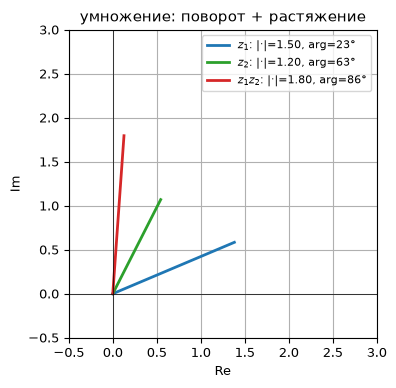

|z1·z2| = 1.800 = |z1|·|z2|
arg(z1)+arg(z2) = 1.500 = arg(z1·z2)


In [61]:
# Умножение — это поворот с растяжением
z1 = 1.5*np.exp(1j*0.4)
z2 = 1.2*np.exp(1j*1.1)
z12 = z1*z2

fig, ax = plt.subplots(figsize=(5, 4))
for zz, name, c in [(z1, '$z_1$', 'tab:blue'), (z2, '$z_2$', 'tab:green'), (z12, '$z_1 z_2$', 'tab:red')]:
    ax.plot([0, zz.real], [0, zz.imag], c, lw=2,
            label=f'{name}: |·|={abs(zz):.2f}, arg={np.degrees(np.angle(zz)):.0f}°')
ax.axhline(0, c='k', lw=.5); ax.axvline(0, c='k', lw=.5)
ax.set_aspect('equal'); ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
ax.set_xlabel('Re'); ax.set_ylabel('Im'); ax.legend(fontsize=8)
ax.set_title('умножение: поворот + растяжение')
plt.show()

print(f'|z1·z2| = {abs(z1)*abs(z2):.3f} = |z1|·|z2|')
print(f'arg(z1)+arg(z2) = {np.angle(z1)+np.angle(z2):.3f} = arg(z1·z2)')

In [62]:
# Фокус 1: корни из −9 через формулу Эйлера
print('−9 = 9·e^{j(π+2πk)}  =>  z_k = 3·e^{j(π/2+πk)}:')
for k in range(2):
    zk = 3*np.exp(1j*(np.pi/2 + np.pi*k))
    print(f'  z_{k} = {zk.real:+.1f} {zk.imag:+.1f}j   (z² = {zk**2})')

# Фокус 2: cos x = 2 — решения комплексные
y1, y2 = 2 + np.sqrt(3), 2 - np.sqrt(3)          # корни y² − 4y + 1 = 0, y = e^{jx}
x1, x2 = -1j*np.log(y1), -1j*np.log(y2)          # x = −j·ln(y)
print(f'\ncos x = 2:  x1 = {x1:.4f},  x2 = {x2:.4f}')
print(f'проверка: cos(x1) = {np.cos(x1):.6f},  cos(x2) = {np.cos(x2):.6f}')

−9 = 9·e^{j(π+2πk)}  =>  z_k = 3·e^{j(π/2+πk)}:
  z_0 = +0.0 +3.0j   (z² = (-9+1.102182119232618e-15j))
  z_1 = -0.0 -3.0j   (z² = (-9+3.3065463576978537e-15j))

cos x = 2:  x1 = -0.0000-1.3170j,  x2 = 0.0000+1.3170j
проверка: cos(x1) = 2.000000-0.000000j,  cos(x2) = 2.000000-0.000000j


---
## 2. Сигнал — это вектор *(слайды 9–13)*

**Основная идея:** сигнал $f$ — это N-мерный вектор в пространстве $\mathbb{R}^N$:

$$f = (f_1, f_2) \in \mathbb{R}^2,\qquad f = (f_1, f_2, f_3) \in \mathbb{R}^3,\qquad
f = (f_1, f_2, \ldots, f_N) \in \mathbb{R}^N$$

«Сигнал — это N-мерный вектор!!!» N отсчётов — N координат. А при $N \to \infty$
дискретный вектор превращается в непрерывную функцию: $f \to f(t)$.

Как только сигнал стал вектором, вся линейная алгебра — в нашем распоряжении:

| Понятие | Формула в $\mathbb{R}^2$ |
|---|---|
| **Норма** (длина) | $\|f\| = \sqrt{f_1^2 + f_2^2}$ |
| **Расстояние** | $\|f-g\| = \sqrt{(f_1-g_1)^2 + (f_2-g_2)^2}$ |
| **Скалярное произведение** | $(f, g) = \|f\|\cdot\|g\|\cos\theta$ |
| **Коэффициент корреляции** | $r = \dfrac{(f,g)}{\|f\|\cdot\|g\|} = \dfrac{f_1 g_1 + f_2 g_2}{\sqrt{f_1^2+f_2^2}\sqrt{g_1^2+g_2^2}}$ |

Скалярное произведение — «сила связи» между векторами. Коэффициент корреляции $r$ —
это косинус угла между сигналами: $r=\pm 1$ — векторы коллинеарны (сигналы «одинаковые»),
$r=0$ — ортогональны («непохожи»). Угол между векторами в $\mathbb{R}^N$:
$\alpha = \arccos\frac{(x, y)}{\|x\|\|y\|}$. Пример со слайда 13: $x=(1,0,0,0)$,
$y=(1,1,1,1)$, тогда $(x,y)=1$, $\|x\|=1$, $\|y\|=2$ и $\alpha = \arccos\frac{1}{1\cdot 2} = \pi/3$.

Для глубокого понимания темы (и вообще линейной алгебры) очень рекомендуются лекции
канала **3Blue1Brown** «Сущность линейной алгебры» (лекция 9 — про скалярное произведение).


f и g (похожие) : |f|= 3.46  (f,g)=   8.00  r=+0.667  угол= 48.2°
f и h (шум)      : |f|= 3.46  (f,g)=  -0.99  r=-0.153  угол= 98.8°


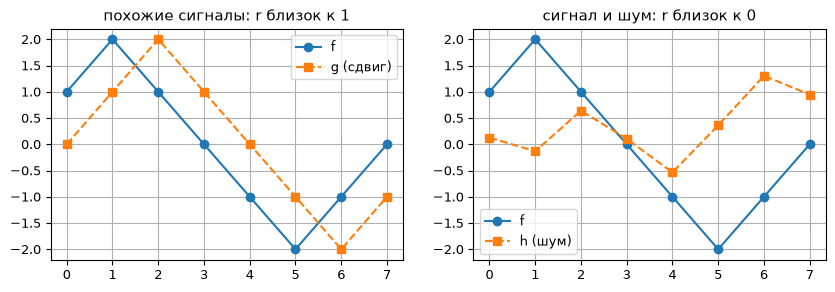

In [63]:
# Два «похожих» сигнала и шум — сравним как векторы
f = np.array([1, 2, 1, 0, -1, -2, -1, 0], float)                  # «пила»
g = np.roll(f, 1)                                                  # сдвинутая пила — похожа
rng = np.random.default_rng(0)
h = rng.normal(size=8)                                             # шум

def vec_info(a, b, name):
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    dot = a @ b
    r = dot / (na * nb)
    ang = np.degrees(np.arccos(np.clip(r, -1, 1)))
    print(f'{name}: |f|={na:5.2f}  (f,g)={dot:7.2f}  r={r:+.3f}  угол={ang:5.1f}°')

vec_info(f, g, 'f и g (похожие) ')
vec_info(f, h, 'f и h (шум)      ')

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(f, 'o-', label='f'); ax[0].plot(g, 's--', label='g (сдвиг)')
ax[0].legend(); ax[0].set_title('похожие сигналы: r близок к 1')
ax[1].plot(f, 'o-', label='f'); ax[1].plot(h, 's--', label='h (шум)')
ax[1].legend(); ax[1].set_title('сигнал и шум: r близок к 0')
plt.show()

---
## 3. Ортонормированный базис: от $\mathbb{R}^N$ к пространству функций *(слайды 14–16)*

Векторы $v_1, v_2$ образуют **ортонормированный базис** $\mathbb{R}^2$, если

$$\|v_1\| = \|v_2\| = 1, \qquad (v_1, v_2) = 0$$

Тогда любой вектор раскладывается по базису, а **координаты — это скалярные произведения**:

$$\hat f = C_1 v_1 + C_2 v_2, \qquad C_1 = (f, v_1), \quad C_2 = (f, v_2)$$

(в $\mathbb{R}^N$ — то же самое: $f = \sum_i C_i v_i$, где $C_i = (f, v_i)$ — проекция
вектора $f$ на $v_i$). Система координат может быть любой — повёрнутой, «косой»:
разложение всё равно возможно, а длина вектора (энергия сигнала!) не зависит от базиса.

**Ключевой вопрос слайда 16:** а нельзя ли ввести понятие базиса в пространстве функций?
Можно! Для функций на отрезке $[a, b]$ вводим скалярное произведение с нормировкой
на длину отрезка:

$$(f, g) = \frac{1}{b-a}\int_a^b f(t)\,g(t)\,dt$$

Тогда $\|f\| = \sqrt{\frac{1}{b-a}\int_a^b f^2(t)dt}$, а если система функций
$\{\varphi_k\}$ удовлетворяет $(\varphi_m, \varphi_n) = 0$ при $m \ne n$ и
$(\varphi_n, \varphi_n) = \|\varphi_n\|^2 = 1$ — это **ортонормированный базис**, и

$$f(t) = \sum_k C_k\,\varphi_k(t), \qquad C_k = (f, \varphi_k) = \frac{1}{b-a}\int_a^b f(t)\,\varphi_k(t)\,dt$$

Всё ровно как в $\mathbb{R}^N$ — только вместо суммы по координатам интеграл по времени.


In [64]:
# Координаты — скалярные произведения: проверим на повёрнутом базисе
teta = np.radians(30)
v1, v2 = np.array([1., 0.]), np.array([0., 1.])                # стандартный базис
u1, u2 = np.array([np.cos(teta), np.sin(teta)]), \
         np.array([-np.sin(teta), np.cos(teta)])                # он же, повёрнутый на 30°

f = np.array([2., 1.])
C = [f @ v1, f @ v2]          # координаты в стандартном базисе
D = [f @ u1, f @ u2]          # координаты в повёрнутом
print('координаты в базисе (v1, v2):', C)
print('координаты в базисе (u1, u2):', np.round(D, 4))
print('сборка обратно:', np.round(D[0]*u1 + D[1]*u2, 10), '= f')
print('длина вектора не зависит от базиса:', np.hypot(*C), '=', round(np.hypot(*D), 12))

координаты в базисе (v1, v2): [np.float64(2.0), np.float64(1.0)]
координаты в базисе (u1, u2): [ 2.2321 -0.134 ]
сборка обратно: [2. 1.] = f
длина вектора не зависит от базиса: 2.23606797749979 = 2.2360679775


---
## 4. Разложение в ряд Фурье *(слайды 17–18)*

Система функций

$$\{1,\ \sqrt{2}\cos t,\ \sqrt{2}\cos 2t, \ldots,\ \sqrt{2}\sin t,\ \sqrt{2}\sin 2t, \ldots\}$$

ортонормирована на отрезке $[-\pi, \pi]$ (со скалярным произведением с весом $\frac{1}{2\pi}$).
Разложение по этому базису — это и есть **тригонометрический ряд Фурье**:

$$f(t) = \alpha_0 + \alpha_1\sqrt{2}\cos t + \alpha_2\sqrt{2}\cos 2t + \ldots
+ \beta_1\sqrt{2}\sin t + \beta_2\sqrt{2}\sin 2t + \ldots$$

Коэффициенты — как всегда, скалярные произведения (проекции на базисные функции):

$$\alpha_0 = (f, 1) = \frac{1}{2\pi}\int_{-\pi}^{\pi} f(t)\,dt, \qquad
\alpha_k = (f, \sqrt{2}\cos kt) = \frac{\sqrt{2}}{2\pi}\int_{-\pi}^{\pi} f(t)\cos kt\,dt, \qquad
\beta_k = (f, \sqrt{2}\sin kt) = \frac{\sqrt{2}}{2\pi}\int_{-\pi}^{\pi} f(t)\sin kt\,dt$$

**Комплексный ряд Фурье** (слайд 18) — то же самое, но в более компактном базисе
$\{\ldots, e^{-2jt}, e^{-jt}, 1, e^{jt}, e^{2jt}, \ldots\} = \{e^{jkt}\}_{k\in\mathbb{Z}}$
(суммирование ведётся по **всем** целым $k$ — не только по положительным!):

$$f(t) = \sum_{k=-\infty}^{\infty} C_k\, e^{jkt}, \qquad
C_k = \frac{1}{2\pi}\int_{-\pi}^{\pi} f(t)\, e^{-jkt}\,dt$$

Если период не $2\pi$, а $T$ (т.е. $\omega_0 = 2\pi/T$):

$$f(t) = \sum_{k=-\infty}^{\infty} C_k\, e^{jk\omega_0 t}, \qquad
C_k = \frac{1}{T}\int_{-T/2}^{T/2} f(t)\, e^{-jk\omega_0 t}\,dt$$

Модуль $|C_k|$ — **амплитудный спектр**, аргумент $\arg C_k$ — **фазовый спектр**.
Для вещественного сигнала $C_{-k} = \overline{C_k}$ (спектрий симметричен).


In [65]:
# Проверим ортонормированность тригонометрической системы (матрица Грама)
t = np.linspace(-np.pi, np.pi, 4001)

def sp2pi(f_, g_):                       # скалярное произведение с весом 1/(2π)
    return np.trapezoid(f_*g_, t)/(2*np.pi)

basis = [np.ones_like(t)]
names = ['1']
for k in (1, 2, 3):
    basis += [np.sqrt(2)*np.cos(k*t), np.sqrt(2)*np.sin(k*t)]
    names += [f'√2·cos{ k}t', f'√2·sin{ k}t']

G = np.array([[sp2pi(a, b) for b in basis] for a in basis])
print('матрица скалярных произведений ( должна быть единичной ):')
print(np.round(G, 10))

матрица скалярных произведений ( должна быть единичной ):
[[ 1.  0.  0. -0. -0.  0. -0.]
 [ 0.  1. -0.  0.  0. -0. -0.]
 [ 0. -0.  1. -0.  0. -0. -0.]
 [-0.  0. -0.  1.  0.  0.  0.]
 [-0.  0.  0.  0.  1.  0. -0.]
 [ 0. -0. -0.  0.  0.  1.  0.]
 [-0. -0. -0.  0. -0.  0.  1.]]


αk (при √2·cos kt): {0: -0.0, 1: -0.0, 2: -0.0, 3: -0.0}
βk≠0 (при √2·sin kt): {1: 0.9003, 3: 0.3001, 5: 0.1801, 7: 0.1286, 9: 0.1, 11: 0.0818, 13: 0.0693, 15: 0.06, 17: 0.053, 19: 0.0474, 21: 0.0429, 23: 0.0391, 25: 0.036}


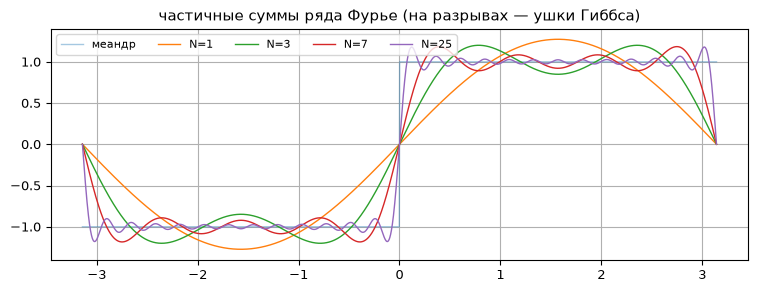

In [66]:
# Разложим меандр в ряд Фурье: коэффициенты = скалярные произведения
sq = np.sign(np.sin(t))                                   # меандр ±1

C_cos = {k: sp2pi(sq, np.sqrt(2)*np.cos(k*t)) for k in range(4)}
C_sin = {k: sp2pi(sq, np.sqrt(2)*np.sin(k*t)) for k in range(1, 26)}
print('αk (при √2·cos kt):', {k: round(float(v), 6) for k, v in C_cos.items()})
print('βk≠0 (при √2·sin kt):', {k: round(float(v), 4) for k, v in C_sin.items() if abs(v) > 1e-6})

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t, sq, lw=1, alpha=.4, label='меандр')
for N in (1, 3, 7, 25):
    s = C_cos[0]*np.ones_like(t)
    for k in range(1, N+1):
        s += C_cos.get(k, 0)*np.sqrt(2)*np.cos(k*t) + C_sin.get(k, 0)*np.sqrt(2)*np.sin(k*t)
    ax.plot(t, s, lw=1, label=f'N={N}')
ax.legend(ncol=5, fontsize=8)
ax.set_title('частичные суммы ряда Фурье (на разрывах — ушки Гиббса)')
plt.show()

In [67]:
# Комплексный ряд Фурье: C_k = (1/2π)∫ f(t)e^{−jkt} dt
def Ck(k, f_=sq):
    return np.trapezoid(f_*np.exp(-1j*k*t), t)/(2*np.pi)

for k in (-3, -1, 0, 1, 3):
    print(f'C[{k:+d}] = {Ck(k):+.4f}')
print(f'\nC[−1] = {Ck(-1):+.4f} = conj(C[+1]) — спектр вещественного сигнала симметричен')
print('β1 =', round(float(C_sin[1]), 4), '= −√2·Im(C1) =', round(-np.sqrt(2)*Ck(1).imag, 4),
      '— коэффициенты связаны попарно')

C[-3] = -0.0000+0.2122j
C[-1] = -0.0000+0.6366j
C[+0] = -0.0000+0.0000j
C[+1] = -0.0000-0.6366j
C[+3] = -0.0000-0.2122j

C[−1] = -0.0000+0.6366j = conj(C[+1]) — спектр вещественного сигнала симметричен
β1 = 0.9003 = −√2·Im(C1) = 0.9003 — коэффициенты связаны попарно


---
## 5. Дискретное преобразование Фурье *(слайд 19)*

Сигнал из $N$ отсчётов $f = (f_0, f_1, \ldots, f_{N-1})$ — вектор в $\mathbb{R}^N$
(точнее, в $\mathbb{C}^N$). Мы знаем: коэффициент разложения $C_k = (f, e_k)$.
Каким должен быть базисный вектор $e_k$? Дискретными «гармониками» с шагом
$\Delta\omega = 2\pi/N$:

$$e_k = \left(1,\ e^{jk\Delta\omega},\ e^{j2k\Delta\omega},\ \ldots,\ e^{j(N-1)k\Delta\omega}\right)$$

Тогда $f = \sum_{k=0}^{N-1} C_k e_k$, и получается пара **ДПФ** (учитывая $\|e_k\|^2 = N$):

$$C_k = \frac{1}{N}\sum_{i=0}^{N-1} f_i\, e^{-j\frac{2\pi}{N}ki}
\qquad\Longleftrightarrow\qquad
f_i = \sum_{k=0}^{N-1} C_k\, e^{+j\frac{2\pi}{N}ki}$$

ДПФ — это буквально вычисление N скалярных произведений сигнала-вектора с N дискретными
экспонентами. Ровно это делает `numpy.fft.fft` (с точностью до множителя $1/N$).


In [68]:
# ДПФ «на пальцах»: матрица скалярных произведений + сравнение с fft
N = 16
n = np.arange(N)
f = np.cos(2*np.pi*2*n/N) + 0.5*np.cos(2*np.pi*5*n/N)     # два «тона»: k=2 и k=5

W = np.exp(2j*np.pi*np.outer(np.arange(N), n)/N)          # строки — векторы e_k
C = (W.conj() @ f)/N                                      # C_k = (f, e_k)/N
f_rec = (W.T @ C).real                                    # обратное ДПФ

print('ненулевые гармоники:')
for k in range(N):
    if abs(C[k]) > 1e-12:
        print(f'  k={k:2d}: |C_k|={abs(C[k]):.3f},  arg C_k={np.angle(C[k]):+.2f} рад')
print('  (k=14 ≡ −2 и k=11 ≡ −5 по модулю N: «отрицательные» частоты wrap-ятся)')

print('\nсовпадает с numpy.fft.fft:', np.allclose(C, np.fft.fft(f)/N))
print('обратное ДПФ восстанавливает сигнал:', np.allclose(f_rec, f))

ненулевые гармоники:
  k= 2: |C_k|=0.500,  arg C_k=+0.00 рад
  k= 5: |C_k|=0.250,  arg C_k=-0.00 рад
  k=11: |C_k|=0.250,  arg C_k=-0.00 рад
  k=14: |C_k|=0.500,  arg C_k=+0.00 рад
  (k=14 ≡ −2 и k=11 ≡ −5 по модулю N: «отрицательные» частоты wrap-ятся)

совпадает с numpy.fft.fft: True
обратное ДПФ восстанавливает сигнал: True


---
## 6. Спектр периодической последовательности прямоугольных импульсов *(слайды 20–21)*

Спектр периодической последовательности прямоугольных импульсов (амплитуда $A$,
длительность $\tau$, период $T$) — это множество гармоник на кратных частотах
$\omega_n = \frac{2\pi}{T}n$ с огибающей вида $\operatorname{sinc}$:

$$C_n = \frac{A\tau}{T}\cdot\frac{\sin(\omega_n\tau/2)}{\omega_n\tau/2}
= \frac{A}{Q}\,\operatorname{sinc}\!\left(\frac{n}{Q}\right),\qquad
\operatorname{sinc}(x)=\frac{\sin\pi x}{\pi x}$$

где $Q = T/\tau$ — **скважность**. В радиолокации скважность — важный показатель работы
импульсных радиоэлектронных систем; в РЛС она может достигать тысяч.

**Вопросы для самопроверки** (слайд 21):
* частота первой гармоники $f_1 = 1/T$ — шаг между «палками» спектра;
* $S(0) = C_0 = A\tau/T = A/Q$ — постоянная составляющая (среднее значение сигнала);
* нули огибающей — на частотах, кратных $1/\tau$: в лепесток попадает ровно $Q$ гармоник.

Примеры спектров для разных скважностей — как на картинках с ru.dspib.org (слайд 21):
чем больше $Q$, тем гуще гармоники и тем ниже постоянная составляющая.


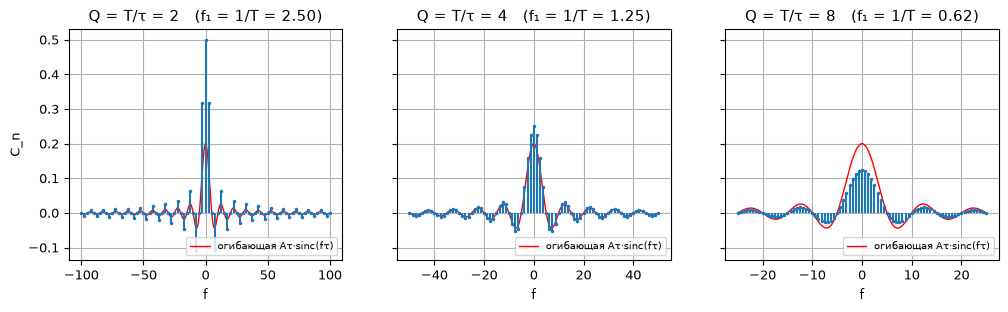

Ответы на вопросы самопроверки (для Q=4):
  f1 = 1/T = 1.25   (расстояние между гармониками)
  S(0) = A·τ/T = A/Q = 0.25   (среднее значение сигнала)


In [69]:
# Спектр периодической последовательности прямоугольных импульсов
A, tau = 1.0, 0.2

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, Q in zip(axes, [2, 4, 8]):
    T = Q*tau
    k = np.arange(-40, 41)
    Cn = (A/Q)*np.sinc(k/Q)                       # гармоники
    fk = k/T                                      # частоты гармоник n/T
    f_dense = np.linspace(-40/T, 40/T, 1000)
    ax.plot(f_dense, A*tau*np.sinc(f_dense*tau), 'r-', lw=1, label='огибающая Aτ·sinc(fτ)')
    m = ax.stem(fk, Cn, basefmt=' ', markerfmt='.')
    m.markerline.set_markersize(3)
    ax.set_title(f'Q = T/τ = {Q}   (f₁ = 1/T = {1/T:.2f})')
    ax.set_xlabel('f'); ax.legend(fontsize=7, loc='lower right')
axes[0].set_ylabel('C_n')
plt.show()

print('Ответы на вопросы самопроверки (для Q=4):')
Q = 4; T = Q*tau
print(f'  f1 = 1/T = {1/T:.2f}   (расстояние между гармониками)')
print(f'  S(0) = A·τ/T = A/Q = {A/Q}   (среднее значение сигнала)')

---
## 7. Переход к непериодическим сигналам. Преобразование Фурье *(слайды 22–24)*

Что будет, если увеличивать период повторения $T$? (слайд 22):

* расстояние между гармониками $\Delta\omega = \frac{2\pi}{T}$ **обратно пропорционально** $T$ — гармоники сближаются;
* амплитуды гармоник уменьшаются — средняя мощность сигнала на одном периоде «размазывается».

При $T \to \infty$ периодический сигнал становится непериодическим: гармоники сливаются
в сплошную линию, а их амплитуды становятся бесконечно малыми.

**Вывод формулы** (слайды 23–24). Так как $\Delta\omega = \frac{2\pi}{T}$, множитель
$\frac{1}{T}$ переходит в бесконечно малое приращение частоты: $\frac{1}{T} \to \frac{d\omega}{2\pi}$,
сумма $\sum$ превращается в интеграл $\int$, и $n\Delta\omega \to \omega$. Получаем пару
**преобразования Фурье**:

$$\boxed{\ S(\omega) = \int_{-\infty}^{\infty} s(t)\, e^{-j\omega t}\,dt
\qquad\text{— прямое}\ }$$

$$\boxed{\ s(t) = \frac{1}{2\pi}\int_{-\infty}^{\infty} S(\omega)\, e^{j\omega t}\,d\omega
\qquad\text{— обратное}\ }$$

**Определение (слайд 24):** преобразование Фурье — это разложение $s(t)$ в сумму
(интеграл) экспоненциальных функций вида $e^{j\omega t}$, т.е. разложение по «непрерывному
базису» из гармонических колебаний всех частот.


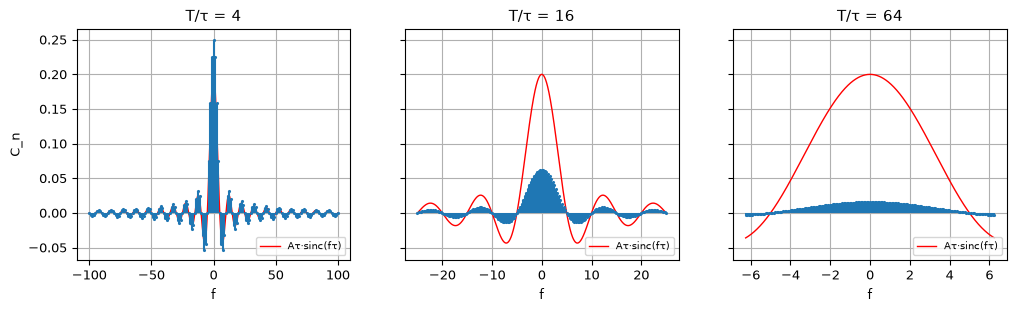

In [70]:
# Гармоники сливаются в сплошной спектр при T → ∞
A, tau = 1.0, 0.2
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, Q in zip(axes, [4, 16, 64]):
    T = Q*tau
    k = np.arange(-80, 81)
    Cn = (A/Q)*np.sinc(k/Q)
    fk = k/T
    f_dense = np.linspace(-80/T, 80/T, 1200)
    ax.plot(f_dense, A*tau*np.sinc(f_dense*tau), 'r-', lw=1, label='Aτ·sinc(fτ)')
    m = ax.stem(fk, Cn, basefmt=' ', markerfmt='.')
    m.markerline.set_markersize(2.5)
    ax.set_title(f'T/τ = {Q}')
    ax.set_xlabel('f'); ax.legend(fontsize=7, loc='lower right')
axes[0].set_ylabel('C_n')
plt.show()

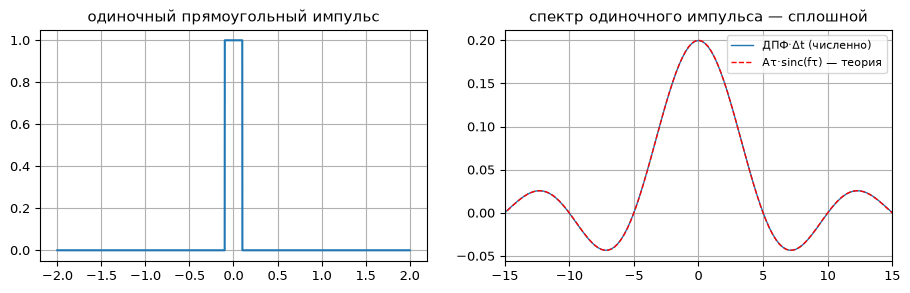

In [71]:
# Спектр одиночного прямоугольного импульса: ДПФ длинного кадра ≈ непрерывное ПФ
M = 8192
T_view = 4.0
t2 = np.linspace(-T_view/2, T_view/2, M, endpoint=False)
dt = t2[1] - t2[0]
x = np.where(np.abs(t2) < tau/2, A, 0.0)             # одиночный импульс длительности τ

X = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(x)))*dt
f_ax = np.fft.fftshift(np.fft.fftfreq(M, dt))

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(t2, x); ax[0].set_title('одиночный прямоугольный импульс')
ax[1].plot(f_ax, X.real, lw=1, label='ДПФ·Δt (численно)')
ax[1].plot(f_ax, A*tau*np.sinc(f_ax*tau), 'r--', lw=1, label='Aτ·sinc(fτ) — теория')
ax[1].set_xlim(-15, 15); ax[1].legend(fontsize=8)
ax[1].set_title('спектр одиночного импульса — сплошной')
plt.show()

---
## 8. Примеры других ортогональных систем функций *(слайд 25)*

Гармонические функции — не единственный ортогональный базис. Примеры:

* **многочлены Лежандра** на отрезке $[-1, 1]$:
  $P_n(x) = \frac{1}{2^n n!}\frac{d^n}{dx^n}(x^2-1)^n$;
* **базис Котельникова** (функции отсчётов) — знаменитые $\operatorname{sinc}$-функции,
  сдвинутые на шаг дискретизации: $\varphi_k(t) = \operatorname{sinc}(t/T - k)$. На них
  опирается теорема отсчётов (Котельникова–Шеннона): сигнал с ограниченным спектром
  полностью восстанавливается по отсчётам;
* **функции Уолша**, **вейвлеты** (базис Хаара) — «прямоугольные» и «локальные» альтернативы.

Все эти системы ортогональны — по ним тоже можно раскладывать сигналы, как по векторам.


(φ0, φ2) = -0.006794  — ортогональность
(φ0, φ0) = 0.993247  — нормировка


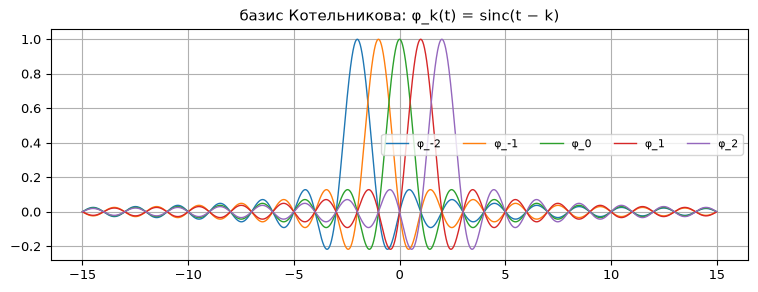

In [72]:
# Базис Котельникова: сдвинутые sinc-функции ортогональны и нормированы
# (на всей оси вес 1/(b−a) уже не нужен: скалярное произведение — просто интеграл)
tt = np.arange(-15, 15, 0.01)
def phi(k, T=1.0):
    return np.sinc((tt - k*T)/T)

print('(φ0, φ2) =', round(np.trapezoid(phi(0)*phi(2), tt), 6), ' — ортогональность')
print('(φ0, φ0) =', round(np.trapezoid(phi(0)*phi(0), tt), 6), ' — нормировка')

fig, ax = plt.subplots(figsize=(9, 3))
for k in (-2, -1, 0, 1, 2):
    ax.plot(tt, phi(k), lw=1, label=f'φ_{k}')
ax.set_title('базис Котельникова: φ_k(t) = sinc(t − k)')
ax.legend(ncol=5, fontsize=8)
plt.show()

---
## 9. Преобразование Лапласа *(слайды 26–27)*

Интеграл Фурье **не всегда сходится**: например, для $\sin(\omega_0 t)$, ступеньки
$\sigma(t)$ или растущего $x(t)$ — «неинтегрируемых» на бесконечности.

**Выход** (слайд 26): умножить сигнал на «гасящий» множитель $e^{-\sigma t}$ и подобрать
$\sigma$ так, чтобы интеграл сходился. Либо, что то же самое, формально заменить в формулах
преобразования Фурье $j\omega$ на $s = \sigma + j\omega$:

$$X(\sigma + j\omega) = \int_{-\infty}^{\infty} x(t)\, e^{-(\sigma + j\omega)t}\,dt,
\qquad
x(t) = \frac{1}{2\pi}\int_{-\infty}^{\infty} X(\sigma + j\omega)\, e^{(\sigma + j\omega)t}\,d\omega$$

Учитывая $d\omega = ds/j$, получаем пару **преобразования Лапласа** (для правосторонних
сигналов, т.е. $x(t)=0$ при $t<0$):

$$\boxed{\,X(s) = \int_0^{\infty} x(t)\, e^{-st}\,dt\,}
\qquad
\boxed{\,x(t) = \frac{1}{2\pi j}\int_{\sigma - j\infty}^{\sigma + j\infty} X(s)\, e^{st}\,ds\,}$$

где $\sigma$ достаточно велико для сходимости интеграла. Другими словами:

$$\mathcal{L}[x(t)] = \mathcal{F}\left[x(t)\,e^{-\sigma t}\right], \qquad X(s) = X(j\omega)\ \text{при}\ s = j\omega$$

**Свойства преобразования Лапласа** (то самое, что «надо раскатать» на слайде 27):

| Свойство | Формула |
|---|---|
| Линейность | $\mathcal{L}[\alpha x + \beta y] = \alpha X(s) + \beta Y(s)$ |
| **Дифференцирование** | $\mathcal{L}[x'] = sX(s) - x(0)$, $\quad \mathcal{L}[x''] = s^2X(s) - sx(0) - x'(0)$ |
| Интегрирование | $\mathcal{L}\left[\int_0^t x\,du\right] = \dfrac{X(s)}{s}$ |
| Смещение | $\mathcal{L}[e^{-at}x(t)] = X(s+a)$ |
| Запаздывание | $\mathcal{L}[x(t-\tau)] = e^{-s\tau}X(s)$ |
| **Умножение на $t$** | $\mathcal{L}[t\,x(t)] = -\dfrac{dX}{ds}$ — дифференцирование образа |
| **Свёртка** | $\mathcal{L}[(x * h)(t)] = X(s)\,H(s)$ — свёртка → произведение! |

**Таблица «времение → образы»** (пригодится в лабе):

| $x(t)$ | $X(s)$ |
|---|---|
| $\delta(t)$ | $1$ |
| $\sigma(t)$ (ступенька) | $\dfrac{1}{s}$ |
| $e^{-at}$ | $\dfrac{1}{s+a}$ |
| $t$ | $\dfrac{1}{s^2}$ |
| $\sin\omega_0 t$ | $\dfrac{\omega_0}{s^2 + \omega_0^2}$ |
| $\cos\omega_0 t$ | $\dfrac{s}{s^2 + \omega_0^2}$ |
| $t\sin\omega_0 t$ | $\dfrac{2\omega_0 s}{(s^2+\omega_0^2)^2}$ |
| $t\cos\omega_0 t$ | $\dfrac{s^2-\omega_0^2}{(s^2+\omega_0^2)^2}$ |

Главная сила: **дифференцирование превращается в умножение на $s$** — линейное
дифференциальное уравнение цепи превращается в алгебраическое. Покажем эту силу на классическом примере — решим уравнение с резонансом, без единой строчки кода.


### Решаем уравнение: $y'' + 4y = \cos 2t$, $\;y(0)=1$, $y'(0)=-1$ — резонанс!

Показываем «главную силу» на классическом примере. Внимание, деталь: собственная
частота левой части $\omega_0 = 2$ **совпадает** с частотой воздействия — это
резонанс (сердце заданий 4–6 лабораторной).

**Шаг 1. Превращаем уравнение в алгебру.** Свойство дифференцирования (с учётом
начальных условий!) даёт $\mathcal{L}[y''] = s^2Y - s\,y(0) - y'(0) = s^2Y - s + 1$,
а из таблицы пар $\mathcal{L}[\cos 2t] = \dfrac{s}{s^2+4}$:

$$(s^2 + 4)\,Y(s) - s + 1 = \frac{s}{s^2+4}
\qquad\Longrightarrow\qquad
Y(s) = \frac{s}{(s^2+4)^2} + \frac{s-1}{s^2+4}$$

**Шаг 2. Обратное преобразование — по таблице.** Второе слагаемое сразу:

$$\frac{s-1}{s^2+4} = \frac{s}{s^2+4} - \frac{1}{2}\cdot\frac{2}{s^2+4}
\;\longrightarrow\; \cos 2t - \tfrac{1}{2}\sin 2t$$

Первое — через новую строку таблицы пар $\mathcal{L}[t\sin\omega_0 t] = \dfrac{2\omega_0 s}{(s^2+\omega_0^2)^2}$:
при $\omega_0 = 2$ имеем $\dfrac{s}{(s^2+4)^2} = \dfrac{1}{4}\cdot\dfrac{4s}{(s^2+4)^2} \to \dfrac{t}{4}\sin 2t$. Итого:

$$\boxed{\,y(t) = \cos 2t - \tfrac{1}{2}\sin 2t + \tfrac{t}{4}\sin 2t\,}$$

**Шаг 3. Проверка.** $y(0) = 1$ ✓. Производная: $y' = -2\sin 2t - \cos 2t +
\frac{1}{4}\sin 2t + \frac{t}{2}\cos 2t$, откуда $y'(0) = -1$ ✓. Прямая подстановка
$y'' + 4y = \cos 2t$ тоже сходится (проверьте!).

**Шаг 4. Читаем ответ через полюса** (мостик к §15 и конспекту section7): у $Y(s)$
полюсы на мнимой оси $\pm 2j$ — причём от первого слагаемого **второго порядка**
(двойные). Простая пара «выдыхает» чистые колебания $\cos 2t - \frac12\sin 2t$,
а **двойной полюс — колебание с линейно растущей амплитудой** $\frac{t}{4}\sin 2t$.
Это и есть резонанс: без потерь отклик нарастает неограниченно. Добавьте потери
(резистор $R$) — полюсы сдвинутся влево, $s = -\alpha \pm j\omega$, неограниченный
рост превратится в насыщение на уровне, пропорциональном добротности
$Q = \omega_0/2\alpha$, — ровно это и измеряется в заданиях 4–6 лабораторной.


> **Для сравнения: чуть сдвинем частоту.** Без резонанса (например, $y''+4y=\cos t$ при нулевых начальных условиях) тем же методом получается
$Y=\dfrac{s}{(s^2+4)(s^2+1)}=\dfrac{s}{3}\!\left(\dfrac{1}{s^2+1}-\dfrac{1}{s^2+4}\right)$, то есть $y=\dfrac{\cos t-\cos 2t}{3}$ —
> **биения**: амплитуда периодически дышит, но остаётся ограниченной. Совпали частоты — полюсы слиплись в
> двойные, и биения превратились в линейный рост. Резонанс — это буквально «слипшиеся полюсы».


---
## 10. Механика–электричество: одни и те же «качели» *(слайд 28)*

Механические и электрические системы описываются **одинаковыми уравнениями**.
Груз массой $m$ на пружине жёсткостью $k$ с вязким трением $b$ под силой $F(t)$
и последовательный RLC-контур с источником напряжения $u(t)$:

$$\underbrace{m\ddot{x} + b\dot{x} + k\,x = F(t)}_{\text{механика}}
\qquad\Longleftrightarrow\qquad
\underbrace{L\ddot{q} + R\dot{q} + \frac{1}{C}\,q = u(t)}_{\text{электрика}}$$

| Механика | Электричество | Роль |
|---|---|---|
| смещение $x(t)$ | заряд $q(t)$ | «координата» |
| скорость $\dot x$ | ток $i = \dot q$ | «движение» |
| масса $m$ | индуктивность $L$ | инерция |
| трение $b$ | сопротивление $R$ | потери |
| жёсткость $k$ | $1/C$ | «возвратная сила» |
| сила $F(t)$ | напряжение $u(t)$ | воздействие |

Осциллограммы получаются **одинаковыми** — можно изучать электричество на качелях
и наоборот. Проверим численно: решим обе задачи (одним и тем же солвером!) и наложим.


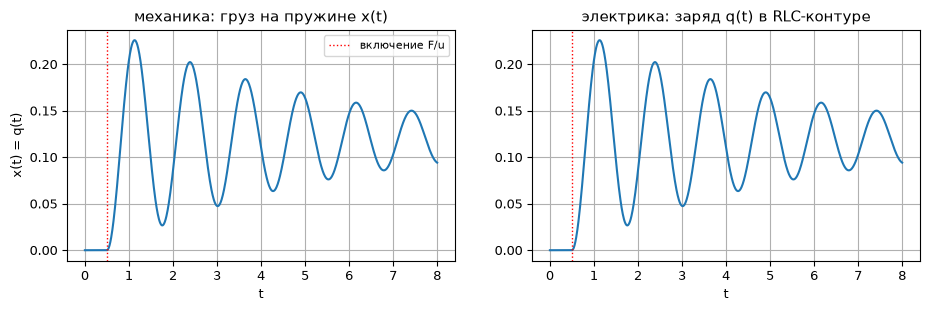

уравнение одно — графики идентичны: m↔L, b↔R, k↔1/C, F↔u, x↔q


In [73]:
# Одно уравнение — две физики: механика и электрика
m_, b_, k_ = 1.0, 0.4, 25.0            # масса, трение, жёсткость
L_, R_, C_ = m_, b_, 1/k_              # «перекладка» в электрические величины

def rhs(tt, y):                        # x1 = x(t)=q(t), x2 = скорость/ток
    F = 0.0 if tt < 0.5 else 3.0       # толчок силы / включение напряжения
    return [y[1], (F - b_*y[1] - k_*y[0])/m_]

sol = solve_ivp(rhs, [0, 8], [0.0, 0.0], t_eval=np.linspace(0, 8, 900),
                rtol=1e-9, atol=1e-11)

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(sol.t, sol.y[0])
ax[0].set_title('механика: груз на пружине x(t)')
ax[1].plot(sol.t, sol.y[0])
ax[1].set_title('электрика: заряд q(t) в RLC-контуре')
for axi in ax:
    axi.set_xlabel('t'); axi.axvline(0.5, color='r', ls=':', lw=1, label='включение F/u')
ax[0].set_ylabel('x(t) = q(t)'); ax[0].legend(fontsize=8)
plt.show()
print('уравнение одно — графики идентичны: m↔L, b↔R, k↔1/C, F↔u, x↔q')

---
## 11. Как рождается передаточная функция *(слайды 29–30)*

У нас есть линейная система — «чёрный ящик»: подаём $x(t)$, снимаем $y(t)$.
Система описывается **линейным дифференциальным уравнением с постоянными коэффициентами**
(потому что $R$, $L$, $C$ — константы).

**Вместо того чтобы решать уравнение для каждого $x(t)$, используем свойство собственной
функции:** если на вход подать $x(t) = e^{st}$, то выходом будет

$$y(t) = H(s)\cdot e^{st}$$

— **тот же самый сигнал**, умноженный на некоторое число $H(s)$. Система не искажает форму
экспоненты, а просто усиливает/ослабляет её в $|H(s)|$ раз и сдвигает по фазе.
$H(s)$ — это и есть **передаточная функция**!

**Вывод** (слайд 30). Типичное уравнение системы:

$$a_n y^{(n)} + \ldots + a_1 y' + a_0 y = b_m x^{(m)} + \ldots + b_1 x' + b_0 x$$

Подставляем $x = e^{st}$, $y = H(s)e^{st}$; тогда $x^{(k)} = s^k e^{st}$, $y^{(k)} = s^k H(s)e^{st}$:

* левая часть: $H(s)\,(a_n s^n + \ldots + a_1 s + a_0)\,e^{st}$
* правая часть: $(b_m s^m + \ldots + b_1 s + b_0)\,e^{st}$

$e^{st}$ — общий множитель в обеих частях, и он **никогда не равен нулю**. Делим на него:

$$\boxed{\,H(s) = \frac{b_m s^m + b_{m-1}s^{m-1} + \ldots + b_1 s + b_0}{a_n s^n + a_{m-1}s^{n-1} + \ldots + a_1 s + a_0}\,}$$

Передаточная функция любой линейной системы с сосредоточенными параметрами — это
**отношение двух многочленов от $s$**, т.е. рациональная дробь. Корни числителя — **нули**,
корни знаменателя — **полюсы**: именно они определяют поведение цепи (об этом — лаба).


In [74]:
# Вывод H(s) «как на слайде 30», но символически (SymPy)
s, t = sp.symbols('s t')
a2, a1, a0, b2, b1, b0 = sp.symbols('a2 a1 a0 b2 b1 b0')
Hs = sp.symbols('H(s)')

x = sp.exp(s*t)
y = Hs*sp.exp(s*t)
ode = sp.Eq(a2*sp.diff(y, t, 2) + a1*sp.diff(y, t) + a0*y,
            b2*sp.diff(x, t, 2) + b1*sp.diff(x, t) + b0*x)
H_solved = sp.solve(ode, Hs)[0]
print('подстановка x=e^{st}, y=H(s)e^{st} даёт:')
print('H(s) =', sp.factor(H_solved))
print('\n— отношение многочленов: рациональная дробь, как и обещано')

подстановка x=e^{st}, y=H(s)e^{st} даёт:
H(s) = (b0 + b1*s + b2*s**2)/(a0 + a1*s + a2*s**2)

— отношение многочленов: рациональная дробь, как и обещано


---
## 12. От физики к импедансу *(слайд 31)*

В гармоническом режиме $u(t) = U_m e^{st}$ производные и интегралы сводятся к умножению
и делению на $s$, поэтому для комплексных амплитуд физические законы становятся «законом Ома»:

* резистор: $u_R = R\,i \;\Rightarrow\; Z_R = R$
* катушка: $u_L = L\frac{di}{dt} \;\Rightarrow\; Z_L = sL$  (на мнимой оси: $j\omega L$)
* конденсатор: $i = C\frac{du_C}{dt} \;\Rightarrow\; Z_C = \dfrac{1}{sC}$  (т.е. $\dfrac{1}{j\omega C}$)

**Импеданс** $Z(s) = U(s)/I(s)$ — «сопротивление» для комплексных амплитуд. С ним работают
все привычные правила: последовательное соединение — $Z = Z_1 + Z_2$, параллельное —
$Z = Z_1 Z_2/(Z_1+Z_2)$, делители напряжения, законы Кирхгофа. Вся «физика» сворачивается
в алгебру комплексных чисел — вот зачем нужны были комплексные очки из §1!

Пример: последовательный RLC-контур, $Z(j\omega) = R + j\omega L + \frac{1}{j\omega C}$.
На частоте $\omega_0 = 1/\sqrt{LC}$ мнимые части взаимно уничтожаются: $|Z|$ проваливается
до $R$ — это **резонанс** (сердце заданий 4–6 лабораторной).


ω0 = 1/√(LC) = 31623 рад/с,  f0 = 5033 Гц
|Z(ω0)| = 10.000 Ом  = R — резонанс!


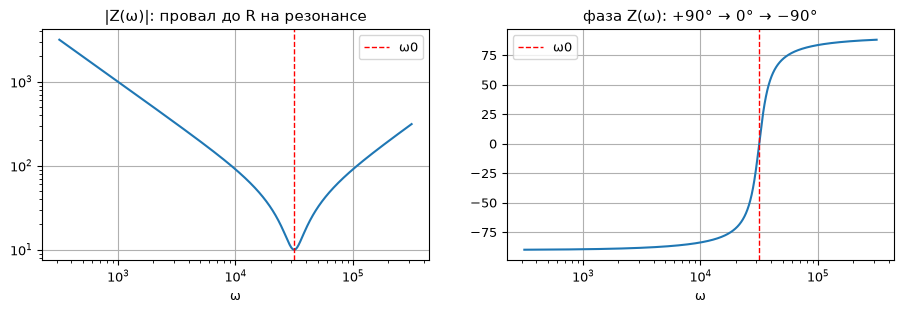

In [75]:
# Импеданс последовательного RLC-контура: |Z(ω)| и фаза
R_, L_, C_ = 10.0, 1e-3, 1e-6
w = np.logspace(2.5, 5.5, 1500)
Z = R_ + 1j*w*L_ + 1/(1j*w*C_)
w0 = 1/np.sqrt(L_*C_)
print(f'ω0 = 1/√(LC) = {w0:.0f} рад/с,  f0 = {w0/2/np.pi:.0f} Гц')
print(f'|Z(ω0)| = {abs(R_ + 1j*w0*L_ + 1/(1j*w0*C_)):.3f} Ом  = R — резонанс!')

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].loglog(w, np.abs(Z)); ax[0].axvline(w0, color='r', ls='--', lw=1, label='ω0')
ax[0].set_title('|Z(ω)|: провал до R на резонансе'); ax[0].set_xlabel('ω'); ax[0].legend()
ax[1].semilogx(w, np.degrees(np.angle(Z))); ax[1].axvline(w0, color='r', ls='--', lw=1, label='ω0')
ax[1].set_title('фаза Z(ω): +90° → 0° → −90°'); ax[1].set_xlabel('ω'); ax[1].legend()
plt.show()

---
## 13. Разряд конденсатора через RL: Лаплас в действии *(слайды 32–34)*

Классическая задача лабы — колебательный разряд. Конденсатор заряжен до $q_0 = CU_0$,
в момент $t=0$ подключается к цепи $R$–$L$. **Второй закон Кирхгофа**:

$$u_L + u_R + u_C = 0:\qquad L\frac{d^2q}{dt^2} + R\frac{dq}{dt} + \frac{q}{C} = 0$$

**Начальные условия:** $q(0) = q_0 = CU_0$; начальный ток $i(0) = \dot q(0) = 0$
(катушка при $t=0^-$ была обесточена, а ток в ней скачком не меняется).

**Решаем через Лапласа.** Напоминание формул (с учётом начальных условий!):

$$\mathcal{L}[q] = Q(s),\qquad
\mathcal{L}[\dot q] = sQ(s) - q(0),\qquad
\mathcal{L}[\ddot q] = s^2 Q(s) - s\,q(0) - \dot q(0)$$

Подставляем в уравнение (вся «дифференциальность» исчезла — осталась алгебра):

$$L(s^2Q - sq_0 - 0) + R(sQ - q_0) + \tfrac{1}{C}Q = 0$$

Откуда изображение заряда:

$$Q(s) = q_0\,\frac{s + R/L}{s^2 + \frac{R}{L}s + \frac{1}{LC}}
= q_0\,\frac{s + 2\alpha}{s^2 + 2\alpha s + \omega_0^2},
\qquad \alpha = \frac{R}{2L},\quad \omega_0 = \frac{1}{\sqrt{LC}}$$

Теперь **вся судьба системы зависит от дискриминанта знаменателя** (слайд 33):
* $\omega_0^2 > \alpha^2$ — комплексные полюсы, **колебательный разряд**: затухающая синусоида $q(t) = \frac{q_0}{\cos\varphi}e^{-\alpha t}\cos(\omega t - \varphi)$, $\omega = \sqrt{\omega_0^2-\alpha^2}$;
* $\omega_0^2 = \alpha^2$ — **критический** случай;
* $\omega_0^2 < \alpha^2$ — вещественные полюсы, **апериодический разряд** (сумма двух экспонент).

Посмотрим все три случая численно.


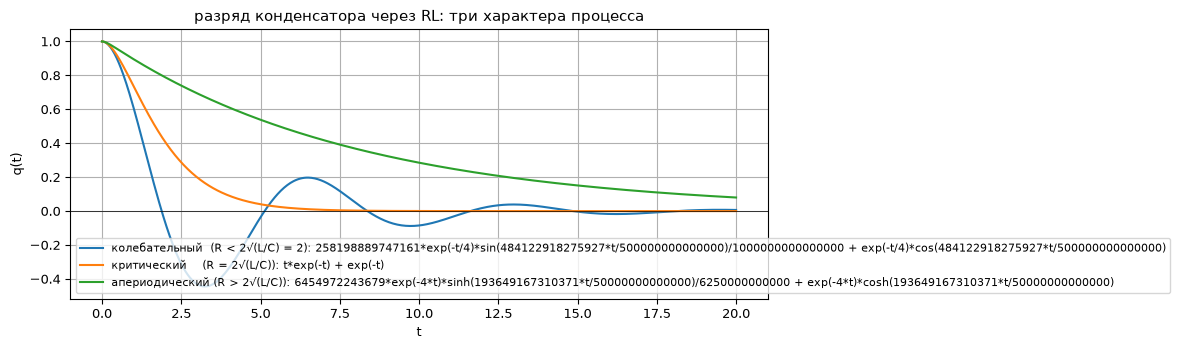

In [76]:
# Три характера разряда: обратное преобразование Лапласа (SymPy)
s, t = sp.symbols('s t', positive=True)
q0_, L_, C_ = 1.0, 1.0, 1.0

fig, ax = plt.subplots(figsize=(9, 3.5))
for R_, case in [(0.5,  'колебательный  (R < 2√(L/C) = 2)'),
                 (2.0,  'критический    (R = 2√(L/C))'),
                 (8.0,  'апериодический (R > 2√(L/C))')]:
    Q = q0_*(s + R_/L_)/(s**2 + R_/L_*s + 1/(L_*C_))
    q = sp.inverse_laplace_transform(Q, s, t).subs(sp.Heaviside(t), 1)
    qf = sp.lambdify(t, q, 'numpy')
    tt = np.linspace(0, 20, 600)
    ax.plot(tt, qf(tt), lw=1.5, label=f'{case}: {sp.nsimplify(q)}')

ax.axhline(0, c='k', lw=.5); ax.set_xlabel('t'); ax.set_ylabel('q(t)')
ax.set_title('разряд конденсатора через RL: три характера процесса')
ax.legend(fontsize=8)
plt.show()

---
## 14. Простейший фильтр *(слайд 35)*

RC-делитель с выхода конденсатора — интегрирующая цепь, **фильтр нижних частот**:

$$H(s) = \frac{1}{1 + sRC} = \frac{1}{1 + s\tau}, \qquad \tau = RC, \qquad \omega_0 = \frac{1}{\tau},\quad f_0 = \frac{1}{2\pi RC}$$

Комплексный коэффициент передачи на мнимой оси $s = j\omega$:

$$|K(j\omega)| = \frac{1}{\sqrt{1 + (\omega/\omega_0)^2}}, \qquad
\varphi(\omega) = -\operatorname{arctg}\frac{\omega}{\omega_0}$$

* полоса пропускания от 0 до частоты среза $\omega_0 = 1/\tau$, на границе $|K| = 1/\sqrt2 \approx 0.7$ (**−3 дБ**);
* переходная характеристика: $h_0(t) = (1 - e^{-t/\tau})\,\sigma(t)$ — за время $\tau$ достигает $\approx 0.63$.

Это ровно **задание 1 лабораторной** (τ ≈ 0.1 мс, $f_0 \approx 1600$ Гц; подсказка методички:
1 кОм · 1 мкФ = 1 мс). И это первый «граф Боде»: после излома на $f_0$ — спад 20 дБ/декаду.


τ = RC = 1.0 мс,  f0 = 1/(2πτ) = 159.2 Гц


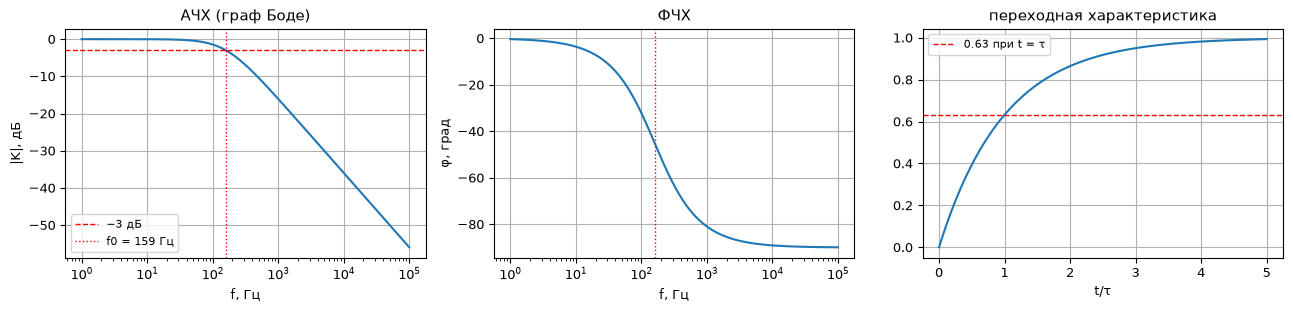

проверка −3 дБ: |K(f0)| = 0.7071 ≈ 0.707


In [77]:
# RC-ФНЧ: АЧХ/ФЧХ и переходная характеристика
R_, C_ = 1e3, 1e-6
tau_ = R_*C_
f0_ = 1/(2*np.pi*tau_)
print(f'τ = RC = {tau_*1e3:.1f} мс,  f0 = 1/(2πτ) = {f0_:.1f} Гц')

f = np.logspace(0, 5, 900)
Hjw = 1/(1 + 2j*np.pi*f*tau_)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].semilogx(f, 20*np.log10(np.abs(Hjw)))
ax[0].axhline(-3, color='r', ls='--', lw=1, label='−3 дБ')
ax[0].axvline(f0_, color='r', ls=':', lw=1, label=f'f0 = {f0_:.0f} Гц')
ax[0].set_title('АЧХ (граф Боде)'); ax[0].set_xlabel('f, Гц'); ax[0].set_ylabel('|K|, дБ'); ax[0].legend(fontsize=8)
ax[1].semilogx(f, np.degrees(np.angle(Hjw)))
ax[1].axvline(f0_, color='r', ls=':', lw=1)
ax[1].set_title('ФЧХ'); ax[1].set_xlabel('f, Гц'); ax[1].set_ylabel('φ, град')
tt = np.linspace(0, 5*tau_, 400)
ax[2].plot(tt/tau_, 1 - np.exp(-tt/tau_))
ax[2].axhline(0.632, color='r', ls='--', lw=1, label='0.63 при t = τ')
ax[2].set_title('переходная характеристика'); ax[2].set_xlabel('t/τ'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

w_half = np.sqrt(1/tau_**2)   # частота, где |K|=1/√2
print(f'проверка −3 дБ: |K(f0)| = {abs(1/(1+2j*np.pi*f0_*tau_)):.4f} ≈ 0.707')

---
## 15. Преобразование Лапласа: пример с вычетом *(слайд 36)*

Как взять обратное преобразование? По определению — контурный интеграл, который
вычисляется **вычетами** (забегание в ТФКП):

$$x(t) = \frac{1}{2\pi j}\int_{\sigma-j\infty}^{\sigma+j\infty} X(s)\,e^{st}\,ds
= \sum_{\text{полюсы}} \operatorname{res}\left[X(s)\,e^{st}\right]$$

Пример со слайда: $X(s) = \dfrac{1}{s+3}$ имеет единственный полюс $s = -3$, поэтому

$$x(t) = \operatorname{res}_{s=-3}\frac{e^{st}}{s+3}
= \lim_{s\to-3}(s+3)\frac{e^{st}}{s+3} = e^{-3t}$$

Каждый полюс «выдыхает» свою экспоненту — ещё одна причина, почему полюса так важны.


In [78]:
# Тот же пример символически: SymPy против вычета вручную
s, t = sp.symbols('s t', positive=True)
X = 1/(s + 3)

x_inv = sp.inverse_laplace_transform(X, s, t).subs(sp.Heaviside(t), 1)
print('обратное преобразование (SymPy): x(t) =', x_inv)

res = sp.limit((s + 3)*X*sp.exp(s*t), s, -3)   # res = lim (s−s0)·X(s)·e^{st}
print('вычет в полюсе s = −3:            x(t) =', res)
print('совпадают:', sp.simplify(x_inv - res) == 0)

обратное преобразование (SymPy): x(t) = exp(-3*t)
вычет в полюсе s = −3:            x(t) = exp(-3*t)
совпадают: True


---
## 16. RC-цепь: дифференциальное уравнение *(слайд 37)*

Рабочий пример семинара — компенсированный делитель (так устроен щуп осциллографа):
вход $x(t)$ → резистор $R_1$ → узел (выход $y(t)$) → резистор $R_2$ → конденсатор $C$ → земля.
Через ветвь течёт один ток:

$$i(t) = \frac{x-y}{R_1} = \frac{y-y_0}{R_2} = C\frac{dy_0}{dt}$$

Исключая $y_0$, получаем дифференциальное уравнение цепи:

$$\boxed{\,C(R_1+R_2)\,y' + y = x + C R_2\,x'\,}$$

При линейно растущем воздействии $x(t) = k\,t$ (правая часть: $kt + CR_2 k$) решение имеет вид

$$y(t) = k\left(a\,(3e^{-t/(4a)} - 3) + t\right) = k\left(t - 3a\left(1 - e^{-t/(4a)}\right)\right)$$

где $a = R_2 C$ (при $R_1 = 3R_2$ имеем $C(R_1+R_2) = 4a$). Проверим это численно двумя
способами: интегрированием ОДУ и аналитической формулой.


a = R2·C = 0.10 мс,  C(R1+R2) = 0.40 мс = 4a


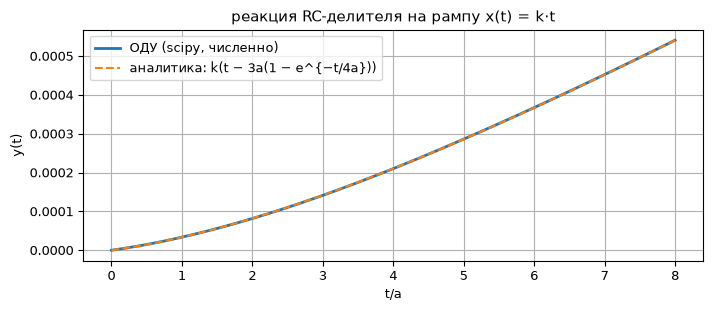

максимальное расхождение: 4.3567843018864675e-07


In [79]:
# RC-делитель: ОДУ численно против аналитики
R1_, R2_, Cc_ = 3e3, 1e3, 0.1e-6
a_ = R2_*Cc_                          # a = R2·C = 0.1 мс
k_ = 1.0

print(f'a = R2·C = {a_*1e3:.2f} мс,  C(R1+R2) = {Cc_*(R1_+R2_)*1e3:.2f} мс = 4a')

def rhs(tt, y):                        # y' = (x + C·R2·x' − y)/(C(R1+R2)),  x = k·t
    return [(k_*tt + Cc_*R2_*k_ - y[0])/(Cc_*(R1_ + R2_))]

sol = solve_ivp(rhs, [0, 8*a_], [0.0], t_eval=np.linspace(0, 8*a_, 500), rtol=1e-10)
tt, y_ode = sol.t, sol.y[0]
y_analytic = k_*(tt - 3*a_*(1 - np.exp(-tt/(4*a_))))

plt.figure(figsize=(8, 3))
plt.plot(tt/a_, y_ode, lw=2, label='ОДУ (scipy, численно)')
plt.plot(tt/a_, y_analytic, '--', lw=1.5, label='аналитика: k(t − 3a(1 − e^{−t/4a}))')
plt.xlabel('t/a'); plt.ylabel('y(t)'); plt.title('реакция RC-делителя на рампу x(t) = k·t')
plt.legend(fontsize=9); plt.show()
print('максимальное расхождение:', np.max(np.abs(y_ode - y_analytic)))

---
## 17. δ-функция и её спектр *(слайд 38)*

**δ-функция (единичный импульс)** — «настолько короткий, что короче не бывает»:
$\delta(t) = \lim_{\varepsilon\to0}\frac{1}{\varepsilon}\operatorname{rect}(t/\varepsilon)$
— импульс длительности $\varepsilon$ и высоты $1/\varepsilon$ (площадь всегда 1).

Ключевые свойства:
* **фильтрующее (записывающее) свойство:** $\displaystyle\int_{-\infty}^{\infty} f(t)\,\delta(t-t_0)\,dt = f(t_0)$;
* $\delta(t)$ — первообразная... точнее, $\sigma(t) = \int_{-\infty}^{t}\delta(u)\,du$ — ступенька Хевисайда (δ — производная ступеньки);
* **спектр δ-функции** — константа (все частоты в равной мере!):

$$S(\omega) = \int_{-\infty}^{\infty}\delta(t)\,e^{-j\omega t}\,dt = 1$$

Это самый «честный» тестовый сигнал: подал δ — получил сразу всю частотную характеристику.


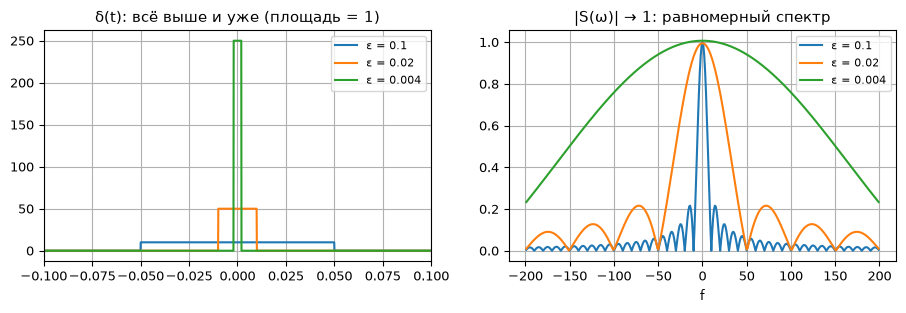

∫f·δε dt = 0.998639   (f(0) = 1.000000)
∫f·δε dt = 0.988774   (f(0) = 1.000000)
∫f·δε dt = 1.037598   (f(0) = 1.000000)


In [80]:
# δ-функция: сужающиеся импульсы и их спектры + фильтрующее свойство
Tview, N = 1.0, 8192
t3 = (np.arange(N) - N//2)*Tview/N
dt3 = t3[1] - t3[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for eps in (0.1, 0.02, 0.004):
    x = np.where(np.abs(t3) < eps/2, 1/eps, 0.0)
    S = np.abs(np.fft.fftshift(np.fft.fft(np.fft.ifftshift(x))))*dt3
    fk = np.fft.fftshift(np.fft.fftfreq(N, dt3))
    m = np.abs(fk) < 200
    ax[0].plot(t3, x, label=f'ε = {eps}')
    ax[1].plot(fk[m], S[m], label=f'ε = {eps}')
ax[0].set_xlim(-0.1, 0.1); ax[0].legend(fontsize=8); ax[0].set_title('δ(t): всё выше и уже (площадь = 1)')
ax[1].legend(fontsize=8); ax[1].set_title('|S(ω)| → 1: равномерный спектр'); ax[1].set_xlabel('f')
plt.show()

# фильтрующее свойство: ∫ f(t)·δε(t) dt → f(0)
f_t = np.exp(-t3)                       # проба в центре окна (t0 = 0): f(0) = 1
for eps in (0.05, 0.01, 0.002):
    d = np.where(np.abs(t3) < eps/2, 1/eps, 0.0)
    print(f'∫f·δε dt = {np.trapezoid(f_t*d, t3):.6f}   (f(0) = {np.exp(0.0):.6f})')

---
## 18. Интеграл свёртки, интеграл Дюамеля, переходная характеристика *(слайды 39–40)*

Произвольный входной сигнал можно представить как континуальную сумму сдвинутых
δ-импульсов с «весами» $x(\tau)$ (фильтрующее свойство!):

$$x(t) = \int_{-\infty}^{\infty} x(\tau)\,\delta(t-\tau)\,d\tau$$

Отклик на δ-импульс — **импульсная характеристика** $h(t)$; из-за стационарности отклик
на $\delta(t-\tau)$ — это $h(t-\tau)$; из-за линейности отклики на сумму — сумма откликов.
Поэтому отклик на произвольное воздействие — **интеграл Дюамеля** (свёртка):

$$\boxed{\,y(t) = \int_{-\infty}^{\infty} x(\tau)\,h(t-\tau)\,d\tau = (x * h)(t)\,}$$

**Переходная характеристика** $h_0(t)$ — реакция на единичную ступеньку $\sigma(t)$.
Так как $\sigma(t) = \int_{-\infty}^{t}\delta(u)du$ (ступенька — первообразная δ), то

$$h_0(t) = \int_{0}^{t} h(u)\,du \qquad\Longleftrightarrow\qquad h(t) = \frac{d\,h_0}{dt}$$

и наоборот — зная $h_0$, тоже можно найти отклик на произвольный сигнал. Заметим:
импульсную характеристику физически «подать» трудно, а переходную — легко (прямоугольник
из генератора!) — поэтому в лабе измеряют именно $h_0(t)$.


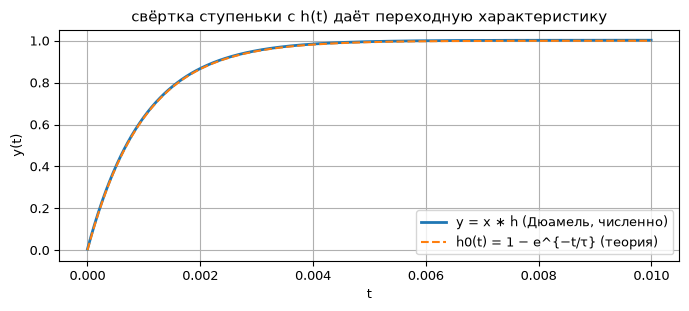

максимальное расхождение: 0.005 — ошибка прямоугольного правила численного интегрирования (шаг dt)


In [81]:
# Интеграл Дюамеля для RC-ФНЧ из §14: свёртка x*h == ступенчатая реакция
dt = tau_/200
tt4 = np.arange(0, 10*tau_, dt)
x_step = np.ones_like(tt4)                 # x(t) = σ(t)
h_rc = (1/tau_)*np.exp(-tt4/tau_)          # h(t) = (1/τ)·e^{−t/τ}
y_duhamel = np.convolve(x_step, h_rc)*dt   # свёртка = интеграл Дюамеля

plt.figure(figsize=(8, 3))
plt.plot(tt4, y_duhamel[:len(tt4)]/1.0, lw=2, label='y = x ∗ h (Дюамель, численно)')
plt.plot(tt4, 1 - np.exp(-tt4/tau_), '--', lw=1.5, label='h0(t) = 1 − e^{−t/τ} (теория)')
plt.xlabel('t'); plt.ylabel('y(t)')
plt.title('свёртка ступеньки с h(t) даёт переходную характеристику')
plt.legend(fontsize=9); plt.show()
print('максимальное расхождение:', np.max(np.abs(y_duhamel[:len(tt4)] - (1 - np.exp(-tt4/tau_)))),
      '— ошибка прямоугольного правила численного интегрирования (шаг dt)')

---
## 19. Находим импульсную характеристику и применяем интеграл Дюамеля *(слайды 41–42)*

Завершаем рабочий пример §16: найдём $h(t)$ RC-делителя и посчитаем реакцию на рампу
$x(t) = kt$ через интеграл Дюамеля — и убедимся, что получится тот же ответ.

Передаточная функция делителя (полагаем $a = R_2 C$, $R_1 = 3R_2$, т.е. $C(R_1+R_2) = 4a$):

$$H(s) = \frac{1 + as}{1 + 4as} = \frac{1}{4}\cdot\frac{s + 1/a}{s + 1/(4a)}$$

Импульсная характеристика = обратное преобразование Лапласа от $H(s) = H(s)\cdot\mathcal{L}[\delta]$
(«полюс выдыхает экспоненту», §15 + доля от «прохода» сигнала):

$$h(t) = \mathcal{L}^{-1}[H(s)] = \frac{\delta(t)}{4} + \frac{3}{16a}\,e^{-t/(4a)}$$

**Интеграл Дюамеля** для $x(t) = kt$:

$$y(t) = (x * h)(t) = \frac{k t}{4} + \frac{3k}{16a}\int_0^t \tau\, e^{-(t-\tau)/(4a)}\,d\tau
= k\left(t - 3a\left(1 - e^{-t/(4a)}\right)\right)$$

— в точности формула слайда 37! На слайде 41 этот интеграл честно считан в WolframAlpha.
Теперь тремя способами: ОДУ (§16), аналитика и численный интеграл Дюамеля.

**Связь между $h(t)$ и $H(s)$** (слайд 42) — главная «формула-мост» семинара:

$$H(s) = \mathcal{L}[h(t)], \qquad h(t) = \mathcal{L}^{-1}[H(s)], \qquad
K(j\omega) = H(s)\big|_{s = j\omega} = \mathcal{F}[h(t)]$$

Линейная система целиком описывается любой из трёх вещей: дифференциальным уравнением,
передаточной функцией $H(s)$ или импульсной характеристикой $h(t)$ — и всё это одно и то же,
переводимое друг в друга.


In [82]:
# h(t) делителя символически: H(s) = (1 + a s)/(1 + 4 a s)
# правильная дробь даёт экспоненту, а «проходная» часть 1/4 — дельту δ(t)/4
s, t = sp.symbols('s t', positive=True)
aa = sp.symbols('a', positive=True)
H = (1 + aa*s)/(1 + 4*aa*s)
H_reg = sp.simplify(H - sp.Rational(1, 4))
h_reg_expr = sp.inverse_laplace_transform(H_reg, s, t).subs(sp.Heaviside(t), 1)
print('H(s) − 1/4 =', sp.simplify(H_reg))
print('обратное преобразование от правильной дроби: h_reg(t) =', h_reg_expr)
print('итого:  h(t) = δ(t)/4 + 3/(16a)·e^{−t/(4a)}')

# и Дюамель символически: y = L^{-1}[ H(s) · L[k t] ]
k = sp.symbols('k', positive=True)
Y = H*sp.laplace_transform(k*t, t, s, noconds=True)
y_expr = sp.simplify(sp.inverse_laplace_transform(Y, s, t).subs(sp.Heaviside(t), 1))
print('\nДюамель символически: y(t) =', sp.expand(y_expr))

H(s) − 1/4 = 3/(4*(4*a*s + 1))
обратное преобразование от правильной дроби: h_reg(t) = 3*exp(-t/(4*a))/(16*a)
итого:  h(t) = δ(t)/4 + 3/(16a)·e^{−t/(4a)}

Дюамель символически: y(t) = -3*a*k + 3*a*k*exp(-t/(4*a)) + k*t


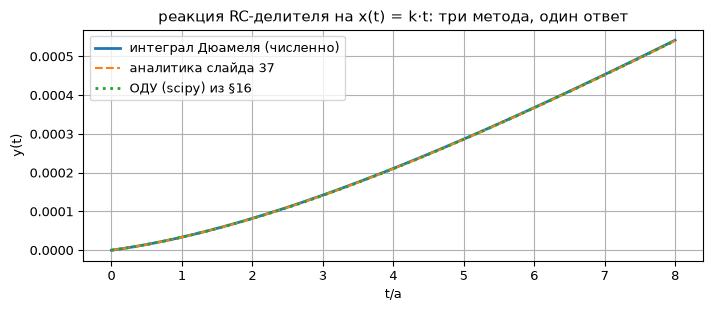

расхождение Дюамель/аналитика: 1.2035552722625999e-06


In [83]:
# Три способа посчитать реакцию на рампу — всё совпадает
dtt = tt[1] - tt[0]                             # локальный шаг сетки из §16
h_reg = (3/(16*a_))*np.exp(-tt/(4*a_))          # регулярная часть h(t) (без δ)
y_duhamel = np.convolve(k_*tt, h_reg)*dtt       # свёртка = интеграл Дюамеля
y_duhamel = y_duhamel[:len(tt)] + k_*tt/4       # обрезаем хвост + вклад δ(t)/4
y_analytic = k_*(tt - 3*a_*(1 - np.exp(-tt/(4*a_))))

plt.figure(figsize=(8, 3))
plt.plot(tt/a_, y_duhamel[:len(tt)], lw=2, label='интеграл Дюамеля (численно)')
plt.plot(tt/a_, y_analytic, '--', lw=1.5, label='аналитика слайда 37')
plt.plot(sol.t/a_, sol.y[0], ':', lw=2, label='ОДУ (scipy) из §16')
plt.xlabel('t/a'); plt.ylabel('y(t)')
plt.title('реакция RC-делителя на x(t) = k·t: три метода, один ответ')
plt.legend(fontsize=9); plt.show()
print('расхождение Дюамель/аналитика:', np.max(np.abs(y_duhamel[:len(tt)] - y_analytic)))

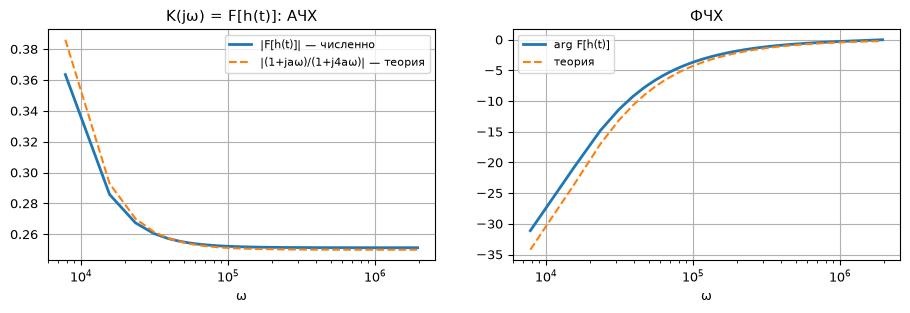

In [84]:
# Связь h(t) и H(s): спектр импульсной характеристики = частотная характеристика
H_num = np.fft.fft(h_reg)*dtt + 0.25          # Фурье регулярной части + константа 1/4 от δ(t)/4
w_ax = 2*np.pi*np.fft.fftfreq(len(h_reg), dtt)
H_exact = (1 + 1j*w_ax*a_)/(1 + 1j*w_ax*4*a_)
m = w_ax > 0

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].semilogx(w_ax[m], np.abs(H_num)[m], lw=2, label='|F[h(t)]| — численно')
ax[0].semilogx(w_ax[m], np.abs(H_exact)[m], '--', lw=1.5, label='|(1+jaω)/(1+j4aω)| — теория')
ax[0].set_title('K(jω) = F[h(t)]: АЧХ'); ax[0].set_xlabel('ω'); ax[0].legend(fontsize=8)
ax[1].semilogx(w_ax[m], np.degrees(np.angle(H_num))[m], lw=2, label='arg F[h(t)]')
ax[1].semilogx(w_ax[m], np.degrees(np.angle(H_exact))[m], '--', lw=1.5, label='теория')
ax[1].set_title('ФЧХ'); ax[1].set_xlabel('ω'); ax[1].legend(fontsize=8)
plt.show()

---
## 20. Элементы цифровой фильтрации: сглаживание (blur) *(слайды 43–46)*

Обозначения: $f(t)$ — изучаемый сигнал, $F(j\omega)$ — его Фурье-спектр,
$h(t)$ — импульсная характеристика фильтра, $H(j\omega)$ — частотная характеристика
фильтра. Преобразование Фурье связывает импульсную характеристику с комплексным
коэффициентом передачи (§19).

Результат прохождения сигнала $x(t)$ через фильтр вычисляется **либо через свёртку**:

$$y(t) = (x * h)(t) = \int x(\tau)\, h(t-\tau)\, d\tau,$$

**либо через обратное преобразование Фурье от произведения спектров** (теорема о свёртке):

$$y(t) = \mathcal{F}^{-1}\left[\,X(j\omega)\cdot H(j\omega)\,\right]$$

**Фильтр «скользящее среднее» (blur)** (слайд 44). В дискретном времени фильтр с окном $N$
усредняет значения по $N$ ближайшим точкам — чем больше окно, тем сильнее сглаживание.
Импульсная характеристика дискретного фильтра — его реакция на единичный импульс.
Подадим $x[i] = [0, 1, 0, 0, \ldots]$ на фильтр, усредняющий 3 соседние точки:
получим $y[i] = [1/3, 1/3, 1/3, 0, \ldots]$ — вот и импульсная характеристика!

Ниже — Python-версия MATLAB-программы со слайда 45: пилообразный сигнал + шум,
фильтрация окном 3 (и шире), спектры до/после, и сравнение «свёртка против произведения
спектров». Небольшой нюанс: FFT-фильтрация — это *циклическая* свёртка, у краёв
(где сигнал обнулён) разница с линейной свёрткой незаметна.


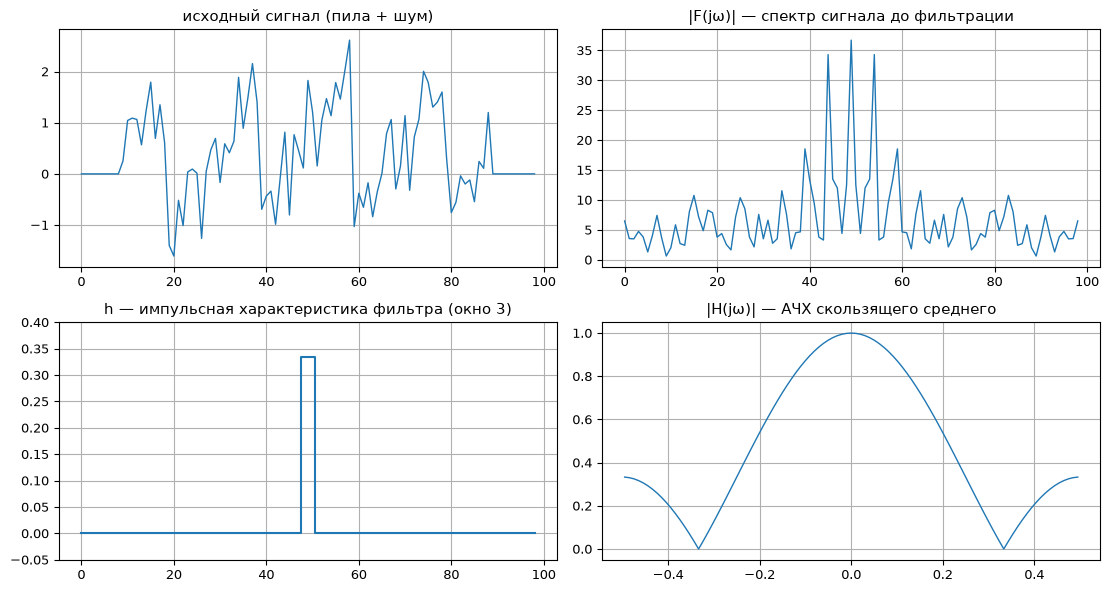

In [85]:
# Python-версия MATLAB-демо со слайда 45: blur = скользящее среднее
rng = np.random.default_rng(7)
N = 99
f_sig = (np.mod(np.arange(1, N+1), 20) - 5)/8 + 0.6*rng.standard_normal(N)
f_sig[:N//10] = 0                       # обнуляем края, как в исходной программе
f_sig[-N//10:] = 0

window = 3
h = np.zeros(N)
h[N//2 - window//2 : N//2 - window//2 + window] = 1/window   # центрированное окно

F = np.fft.fft(f_sig)
Hjw = np.fft.fft(h)
f_blur = np.fft.ifftshift(np.fft.ifft(F*Hjw)).real   # ifftshift: h центрирована в середине кадра

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
ax[0, 0].plot(f_sig, lw=1); ax[0, 0].set_title('исходный сигнал (пила + шум)')
ax[0, 1].plot(np.abs(np.fft.fftshift(F)), lw=1)
ax[0, 1].set_title('|F(jω)| — спектр сигнала до фильтрации')
ax[1, 0].step(np.arange(N), h, where='mid'); ax[1, 0].set_ylim(-0.05, 0.4)
ax[1, 0].set_title('h — импульсная характеристика фильтра (окно 3)')
ax[1, 1].plot(np.fft.fftshift(np.fft.fftfreq(N)), np.abs(np.fft.fftshift(Hjw)), lw=1)
ax[1, 1].set_title('|H(jω)| — АЧХ скользящего среднего')
plt.tight_layout(); plt.show()

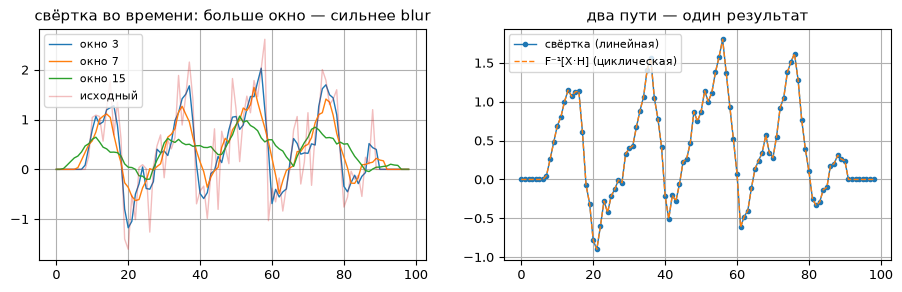

макс. |свёртка − умножение спектров| = 4.440892098500626e-16 — края обнулены, поэтому циклическая свёртка совпадает с линейной


In [86]:
# Результат фильтрации: свёртка во времени == произведение спектров
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for w_ in (3, 7, 15):
    hw = np.zeros(N); hw[N//2 - w_//2 : N//2 - w_//2 + w_] = 1/w_
    ax[0].plot(np.convolve(f_sig, hw, mode='same'), lw=1, label=f'окно {w_}')
ax[0].plot(f_sig, alpha=.3, lw=1, label='исходный')
ax[0].set_title('свёртка во времени: больше окно — сильнее blur')
ax[0].legend(fontsize=8)

w_ = 5
h5 = np.zeros(N); h5[N//2-2:N//2+3] = 1/5
y_conv = np.convolve(f_sig, h5, mode='same')
y_spec = np.fft.ifftshift(np.fft.ifft(np.fft.fft(f_sig)*np.fft.fft(h5))).real
ax[1].plot(y_conv, 'o-', ms=3, lw=1, label='свёртка (линейная)')
ax[1].plot(y_spec, '--', lw=1, label='F⁻¹[X·H] (циклическая)')
ax[1].set_title('два пути — один результат')
ax[1].legend(fontsize=8)
plt.show()
print('макс. |свёртка − умножение спектров| =', np.max(np.abs(y_conv - y_spec)),
      '— края обнулены, поэтому циклическая свёртка совпадает с линейной')

---
## 21. Итоги: целостная картина и связь с лабораторной работой

**Большая картина семинара** — все дороги ведут по кругу:

```
 комплексные числа (§1) ──► векторное пространство сигналов (§2–3)
        │                          │
        │                          ▼
        │                  ортогональные базисы ──► ряды Фурье, ДПФ (§4–6)
        │                          │
        ▼                          ▼
  импедансы (§12)          преобразование Фурье (§7) ──► Лаплас (§9)
        │                          │                        │
        ▼                          │                        ▼
 RLC-цепь: ОДУ (§10, §13) ◄────────┘              передаточная функция H(s) (§11)
        │                                           │
        ▼                                           ▼
 диф. уравнение (§16) ◄──────────────────────►  h(t) = L⁻¹[H(s)] (§19)
        │                                           │
        └──────────► интеграл Дюамеля y = x∗h (§18) ◄┘
                                                    │
                                                    ▼
                        цифровая фильтрация, blur (§20)
```

**Что из этого понадобится в каждом задании лабораторной** (методичка «Пассивные
электрические цепи», МФТИ 2020):

| Задание лабы | Тема | Понятия семинара |
|---|---|---|
| 8.1 | Интегрирующие/дифференцирующие звенья | $H(s)=\frac{1}{1+sRC}$ и $\frac{sRC}{1+sRC}$ (§14), АЧХ/ФЧХ, −3 дБ, $h_0(t)=1-e^{-t/\tau}$, граф Боде |
| 8.2 | RC-звенья 2-го порядка | полюса $H(s)$, три типа процессов (§13), добротность $Q\le 1/2$ у RC-цепей |
| 8.3 | Мостовые схемы (фазовращатель, двойной T-мост) | нули/полюса, ФЧХ, групповая задержка $\tau_g = -d\varphi/d\omega$ |
| 8.4 | Последовательный резонанс | импедансы (§12), $Z(j\omega)$, $\omega_0=1/\sqrt{LC}$, «звон» = комплексные полюса (§13) |
| 8.5 | Параллельный резонанс | дуальность, пересчёт потерь $R = \rho^2/r$ |
| 8.6 | Смешанные резонансы | несколько нулей/полюс, вклад каждого в фазу |

**Три ключевые идеи, которые стоит унести с собой:**

1. **Сигнал — вектор.** Ряды Фурье, ДПФ и преобразование Фурье — это одно и то же:
   скалярные произведения с ортогональным базисом (разделы 2–7).
2. **Экспонента $e^{st}$ — собственная функция линейной цепи.** Отсюда передаточная
   функция, импедансы и вся «алгебра вместо диффуров» (разделы 9–12).
3. **Цепь = $h(t)$ = $H(s)$.** Реакция на любой сигнал — свёртка с $h(t)$;
   в частотной области — умножение на $H(j\omega)$ (разделы 17–20).


---
## 22. Дополнительно: что почитать и посмотреть *(слайд 47)*

* **Юкио Сато** «Занимательная цифровая обработка сигналов» — стилистика и картинки
  этого семинара во многом оттуда; лучшая вводная в ДПС «на пальцах».
* **С. И. Баскаков** «Радиотехнические цепи и сигналы: руководство по решению задач» —
  задачник, идеально дополняющий лабу.
* **C. Alexander, M. Sadiku** «Fundamentals of Electric Circuits» — подробный и наглядный
  учебник по теории цепей (в т.ч. переходные процессы, резонансы).
* **3Blue1Brown** (есть русские переводы): лекции «Сущность линейной алгебры»,
  «Сущность матанализа» — лучшая визуальная интуиция для разделов 2–3 и 9.
* Методичка самой лабы: *Григорьев А. А., Филатов И. В. «Пассивные электрические цепи»,
  МФТИ, 2020* — все задания, формулы и .cir-модели для MicroCap.

*Ноутбук подготовлен как конспект-практикум к семинару по лаб. работе № 18
(РТЦиС). Все ячейки можно и нужно перезапускать, менять параметры и экспериментировать —
это лучший способ «прочувствовать» математику.* 🎓
